# Lab 2: Exploring the Fund's Data

**Time:** about 90 minutes

You've just been handed a raw extract from the Fund's systems: employers, members, monthly contribution
remittances and benefit claims. Before anyone builds a model on it, someone has to understand it. What does
one row mean? What's missing, and why? What looks wrong? What looks *interesting*?

That someone is you. By the end of this notebook you'll have:

- loaded and typed all four tables properly,
- a written list of data-quality issues, each with a proposed fix,
- a handful of business questions worth taking to the claims, compliance and finance teams.

Work through the cells in order. Wherever you see **Your turn**, stop and write the code yourself before
moving on. Suggested answers are at the very end of the notebook, but give it a real try first.

**How the code is written.** Every code cell does one small step and starts with a comment saying what it does.
Read the comment, run the cell, look at the output, then move on. Nothing here is clever on purpose: it's the same
pandas you'd write at work.

In [74]:
import sys; print(sys.executable)

/Users/daud.mabena/Documents/DUBAI/Training1910Labs/DAY1/Labs/work/fund-ai/.venv/bin/python


## Where this lab fits

**What you've done so far.** In Lab 1 you built the workspace for the whole course: a Python environment called
`fund-ai`, a project folder, and Git to keep track of your changes. Nothing has touched the Fund's data yet.

**What you'll do now.** You'll open the four raw tables and get to know them the way an analyst does on their first
week in a new job: what each row means, which values can be trusted, which can't, and what the data says about how the
Fund works.

**Why this comes first.** Every model in the next nine days learns from data like this. A model can't tell a typing
error from a real fact. If a wage of TZS 80 million is really a slip for TZS 8 million, the model will happily learn
from it. The saying in the trade is *"garbage in, garbage out"*. Exploring the data is how you find the garbage before
a model eats it.

**What happens next.** In Lab 3 you'll take the problems you write down today and turn each one into a cleaning rule
in a pipeline that runs the same way every time. From Day 2 onwards, the models use the clean data that comes out of
that pipeline.

### How to read this notebook

Two kinds of text block are new in this version of the labs:

- **Theory** blocks explain an idea from scratch before you use it. Read them even if you've met the idea before: they
  say how it applies to the Fund's data.
- **Where we are** blocks are short summaries between sections: what you've found so far, what comes next, and why.
  If you lose the thread, read back through those.

## 1. Setup

Run the next cells. They import the libraries you need and find the data files. The files can sit next to this
notebook or in `../data/raw/` if you set up the project layout from Lab 1.

In [75]:
# Import the libraries for this lab.
#   numpy  - fast arrays of numbers (pandas is built on it)
#   pandas - tables of data (DataFrames)
#   matplotlib - charts
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [76]:
# Display settings: show more columns, and print numbers with thousand separators and 2 decimals.
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)

# Default chart size (width, height in inches).
plt.rcParams["figure.figsize"] = (9, 4)

In [77]:
# Where are the CSV files?
# If you followed the Lab 1 layout they are in ../data/raw. Otherwise they are next to this notebook.
DATA = Path("../data/raw")
if not (DATA / "members.csv").exists():
    DATA = Path(".")

# The date the extract was taken. Any date after this is impossible.
SNAPSHOT = pd.Timestamp("2026-01-31")

print("Python:", sys.executable)
print("Reading data from:", DATA.resolve())

Python: /Users/daud.mabena/Documents/DUBAI/Training1910Labs/DAY1/Labs/work/fund-ai/.venv/bin/python
Reading data from: /Users/daud.mabena/Documents/DUBAI/Training1910Labs/DAY1/Labs/work/fund-ai/data/raw


### Theory: how a computer holds a table

A spreadsheet looks like a grid of cells, and any cell can hold anything: a number, a word, a date, a formula. Python's
data tools work differently, and knowing how saves a lot of confusion later.

**Columns, not cells.** pandas stores a table (a **DataFrame**) as a set of columns. Each column is a **Series**: a
long list of values that all have the same **data type** (dtype). The main types you'll meet are:

| Type | Holds | Example |
|---|---|---|
| `int64` | whole numbers | number of members reported: `42` |
| `float64` | numbers with decimals, and the special "missing" value `NaN` | a wage: `650000.0` |
| `string` / `object` | text | a region: `"Arusha"` |
| `datetime64` | dates and times | a claim date: `2024-03-15` |
| `bool` | `True` / `False` | "was it paid on time?" |
| `category` | text from a short, fixed list, stored compactly | benefit type: `MATERNITY` |

**Why one type per column.** Because every value in a column has the same type, pandas can store the column as one
compact block of memory and run an operation on all of it at once. That's what makes pandas fast. It's also why one
bad value matters: a single `"N/A"` typed into a column of numbers forces the whole column to be stored as text, and
then you can't add it up.

**Underneath, it's numpy.** Each column is held in a **numpy array**. numpy is the library that does fast arithmetic on
long lists of numbers. You'll rarely call it yourself, but three of its habits (below) explain behaviour in pandas that
otherwise looks strange.

**The index.** Every DataFrame also has an **index**: a label for each row. When you read a CSV the index is just
`0, 1, 2, ...`. You'll mostly ignore it in this lab, but you'll see it on the left of every table pandas prints.

## 2. A few minutes of numpy

pandas is built on numpy arrays. You rarely call numpy directly, but three of its habits explain a lot of
pandas behaviour that otherwise seems strange. Run each cell and read the output before moving on.

**Vectorised arithmetic.** You never loop over rows to compute a contribution. The operation applies to the
whole array at once.

In [78]:
# Four monthly wages, in TZS.
wages = np.array([450_000, 800_000, 1_250_000, 380_000])

# Multiply every wage by 20% in one go - no loop needed.
contribution = wages * 0.20
contribution

array([ 90000., 160000., 250000.,  76000.])

**dtypes matter.** An integer array can't hold a missing value. The moment a value is missing, numpy (and
pandas) switches to float and uses `NaN`. That's why ID numbers, or any very large number, read from a CSV can turn
into `1.04e+08` (scientific notation: 1.04 × 10⁸) if you're careless, and why you'll tell pandas to read IDs as text.

In [79]:
# An array of whole numbers...
a = np.array([1, 2, 3])
# ...and the same array with one missing value (np.nan).
b = np.array([1, 2, np.nan])

# The "dtype" is the type of value the array holds. Notice b had to become float.
print("a:", a.dtype)
print("b:", b.dtype)

a: int64
b: float64


**NaN spreads.** Any arithmetic with NaN gives NaN, and `NaN == NaN` is `False`. Use `np.isnan` or pandas'
`isna()` to test for it, and the `nan`-aware functions when you want to ignore it.

In [80]:
# A normal sum gives nan, because one value is missing.
print("sum:", b.sum())

# np.nansum skips the missing value.
print("nansum:", np.nansum(b))

sum: nan
nansum: 3.0


In [81]:
# NaN is not even equal to itself, so never test for it with ==
print("np.nan == np.nan ->", np.nan == np.nan)

# Use np.isnan (or .isna() in pandas) instead.
print("np.isnan(b) ->", np.isnan(b))

np.nan == np.nan -> False
np.isnan(b) -> [False False  True]


> **Where we are.** You've seen how pandas stores data and why types matter. Now you'll load the four real tables.

### Theory: CSV files, and how the four tables fit together

**A CSV file has no types.** "CSV" means *comma-separated values*. It's plain text: one line per row, with commas
between the values. Open one in Notepad and you'll see something like:

```
member_no,employer_no,date_of_birth,monthly_wage_tzs
00104233,E01120,1985-04-12,650000
```

Nothing in the file says that `00104233` is a label and not a number, or that `1985-04-12` is a date. When pandas reads
the file it **guesses** each column's type from what it sees. It guesses numbers well, and it gets labels wrong: it
reads `00104233` as the number 104233 and drops the leading zeros. That's why you'll tell it which columns are IDs.

**Four tables, linked by keys.** The Fund's data is split into four tables, the way most business systems store it.
Each table describes one kind of thing, and they point at each other through shared ID columns called **keys**:

```
employers ──(employer_no)──► members ──(member_no)──► claims
    │
    └──(employer_no)──► contributions (one row per employer per month)
```

- An **employer** has many **members** working for it.
- An employer sends one **contribution** remittance every month.
- A **member** can lodge several **claims** over their life.

Splitting the data like this avoids repeating information. The employer's sector is stored once in `employers`, not
copied onto every one of that employer's monthly contribution rows. When you need the two together, you **join** them on the key
(Section 11).

## 3. Load the four tables

Two things to notice in the next cells:

- ID columns (`member_no`, `employer_no`, `nida_no`, `phone`) are read as **text**. They're labels, not
  numbers. You'd never add two member numbers together, and reading them as numbers would drop leading
  zeros from phone numbers.
- Dates are **not** parsed yet. You'll do that deliberately in Section 6, so that bad dates show up
  instead of silently disappearing.

In [82]:
# Tell pandas to read these ID columns as text ("string"), not as numbers.
id_cols = {
    "member_no": "string",
    "employer_no": "string",
    "nida_no": "string",
    "phone": "string",
    "claim_no": "string",
    "tin": "string",
}

In [83]:
# Read each CSV file into a DataFrame (a table).
employers = pd.read_csv(DATA / "employers.csv", dtype=id_cols)
members = pd.read_csv(DATA / "members.csv", dtype=id_cols)
contrib = pd.read_csv(DATA / "contributions_monthly.csv", dtype=id_cols)
claims = pd.read_csv(DATA / "claims.csv", dtype=id_cols)

In [84]:
# .shape gives (number of rows, number of columns).
print("employers:    ", employers.shape)
print("members:      ", members.shape)
print("contributions:", contrib.shape)
print("claims:       ", claims.shape)

employers:     (1408, 9)
members:       (61016, 17)
contributions: (127902, 8)
claims:        (13848, 11)


In [85]:
# How much memory does each table use? memory_usage(deep=True) counts the text too. 1e6 bytes = 1 MB.
print("employers:     ", round(employers.memory_usage(deep=True).sum() / 1e6, 1), "MB")
print("members:       ", round(members.memory_usage(deep=True).sum() / 1e6, 1), "MB")
print("contributions: ", round(contrib.memory_usage(deep=True).sum() / 1e6, 1), "MB")
print("claims:        ", round(claims.memory_usage(deep=True).sum() / 1e6, 1), "MB")

employers:      0.2 MB
members:        15.5 MB
contributions:  12.6 MB
claims:         2.2 MB


### The data dictionary

| Table | Column | Meaning |
|---|---|---|
| employers | `employer_no` | Employer registration number |
| | `sector`, `region`, `legal_form` | What the employer does and where |
| | `registration_date`, `status`, `closure_date` | When it registered; whether it's still trading |
| members | `member_no` | Member number, for life |
| | `employer_no` | Current or last employer |
| | `employment_start`, `registration_date` | When the job started; when the member was registered with the Fund |
| | `contribution_months` | Months of contributions on record, including before 2017 |
| | `exit_date`, `exit_reason`, `date_of_death`, `status` | How and when the member left, if they did |
| | `monthly_wage_tzs` | Latest gross monthly wage |
| contributions | `period` | The wage month the contribution is for (`YYYY-MM`) |
| | `members_reported`, `gross_wages_tzs` | From the employer's contribution schedule |
| | `contribution_due_tzs` | 20% of gross wages |
| | `amount_paid_tzs`, `payment_date` | What arrived and when. Empty means not paid by the snapshot date. |
| | `due_date` | Last day of the month after `period` |
| claims | `claim_no`, `member_no`, `benefit_type` | Which claim, whose, for what |
| | `claim_date`, `decision_date`, `status` | When it was lodged and decided; PAID, REJECTED or PENDING |
| | `amount_claimed_tzs`, `amount_paid_tzs` | Amounts. For pensions, the claim amount is the lump sum or first-year amount. |
| | `documents_missing_at_lodging`, `channel`, `branch` | How the claim came in |

### Theory: profiling a table in three commands

**Profiling** means getting a quick picture of a table before you analyse it. Three pandas commands do most of the
work:

- `head()` shows the first five rows. It answers *"what does one row look like?"*
- `info()` lists every column with its type and the number of values that are **not** missing. If a table has 13,800
  rows and a column shows 12,100 non-null values, 1,700 are missing.
- `describe()` summarises each number column with eight statistics.

The `describe()` statistics, in plain words, using a column of claim amounts as the example:

| Statistic | Meaning |
|---|---|
| `count` | how many values are filled in |
| `mean` | the average: add them up and divide by the count |
| `std` | standard deviation: roughly, how far a typical value is from the mean. Small = values bunched together |
| `min`, `max` | the smallest and largest values |
| `25%` | a quarter of the values are below this (the first **quartile**) |
| `50%` | half are below, half above: the **median**, the middle value |
| `75%` | three quarters are below this |

**A trick for spotting errors.** Compare `max` with `75%`. In clean data the largest value is usually a few times the
75th percentile. If it's a hundred times bigger, either something extreme happened or someone typed too many zeros.
`describe()` can't tell you which; it only tells you where to look.

## 4. First look

Start with the claims table. `head()` shows you what a row looks like. `info()` shows types and non-null
counts. `describe()` summarises the numbers.

In [86]:
# The first five rows.
claims.head()

,claim_no,member_no,benefit_type,claim_date,channel,branch,amount_claimed_tzs,documents_missing_at_lodging,status,decision_date,amount_paid_tzs
0,CLM-2017-004967,460366954,UNEMPLOYMENT,2017-01-19,BRANCH,Dodoma,"599,400.00",2,REJECTED,2017-05-30,0.00
1,CLM-2017-000309,432191244,UNEMPLOYMENT,2017-01-20,BRANCH,Tanga,"599,400.00",1,REJECTED,2017-02-23,0.00
2,CLM-2017-010038,240225973,OLD_AGE_PENSION,2017-01-21,EMPLOYER_HR,Tabora,"4,738,400.00",0,PAID,2017-02-12,"4,738,400.00"
3,CLM-2017-005931,371540847,MATERNITY,2017-01-23,BRANCH,Kinondoni,"6,182,400.00",3,REJECTED,2017-04-10,0.00
4,CLM-2017-004652,413793900,OLD_AGE_PENSION,2017-01-26,BRANCH,Temeke,"5,833,700.00",0,PAID,2017-03-01,"5,833,700.00"


In [87]:
# Column names, their types, and how many values are not missing.
claims.info()

<class 'pandas.DataFrame'>
RangeIndex: 13848 entries, 0 to 13847
Data columns (total 11 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   claim_no                      13848 non-null  string 
 1   member_no                     13848 non-null  string 
 2   benefit_type                  13848 non-null  str    
 3   claim_date                    13848 non-null  str    
 4   channel                       13848 non-null  str    
 5   branch                        13848 non-null  str    
 6   amount_claimed_tzs            13848 non-null  float64
 7   documents_missing_at_lodging  13848 non-null  int64  
 8   status                        13848 non-null  str    
 9   decision_date                 13647 non-null  str    
 10  amount_paid_tzs               13647 non-null  float64
dtypes: float64(2), int64(1), str(6), string(2)
memory usage: 2.1 MB


In [88]:
# Count, mean, standard deviation, min, quartiles and max of every numeric column.
claims.describe()

,amount_claimed_tzs,documents_missing_at_lodging,amount_paid_tzs
count,"13,848.00","13,848.00","13,647.00"
mean,"5,230,232.26",0.78,"4,450,056.88"
std,"13,386,799.28",1.03,"13,368,042.77"
min,"418,500.00",0.00,0.00
25%,"1,005,000.00",0.00,0.00
50%,"1,618,400.00",0.00,"1,001,000.00"
75%,"3,210,725.00",1.00,"2,451,400.00"
max,"254,922,000.00",3.00,"254,922,000.00"


Look at `amount_claimed_tzs` in that summary. The maximum is far above the 75th percentile. That's either
a genuinely large claim or a typing error. Keep it in mind; you'll come back to it in Section 8.

**Your turn (1).** Run `head()`, `info()` and `describe()` on `contrib` and `members`. For each table, note
one thing that surprises you. Write it down, because you'll use these notes for the issues log at the end.

In [89]:
# Your code here

> **Where we are.** You've loaded the tables and taken a first look, and you've started noting things that surprise
> you. Before you count or add up anything, you need to be sure what one row means.

### Theory: grain, keys and duplicates

**Grain** is the word for *"what one row represents"*. In `claims` the grain is one claim. In `contributions` it's one
employer in one month. Every question you ask of a table depends on the grain. "How many members do we have?" is
`len(members)` only if each member appears exactly once.

A **key** is the column (or set of columns) that identifies one row. If the grain is "one claim", the key is
`claim_no`, and no two rows should share a `claim_no`. When the grain needs two columns, as in "one employer, one
month", the key is both together, `employer_no` + `period`. That's called a **composite key**.

**Why duplicates are dangerous.** Imagine an employer whose March remittance of TZS 4 million appears twice by mistake.
Any total that includes March is now TZS 4 million too high. Nothing errors and nothing warns you: the sum just comes
out wrong, and it goes into a report.

There are two kinds of duplicate, and they need different treatment:

| Kind | What it looks like | Usual cause |
|---|---|---|
| **Exact duplicate** | every column identical | the same record loaded twice |
| **Key duplicate** | same key, but some columns differ | two versions of the truth: an update, a correction, two source systems |

An exact duplicate is safe to remove. A key duplicate isn't: you have to decide which version is right, and that
decision is a business rule, not a coding trick. That's why the next cells look at each case before changing anything.

## 5. What is one row? Keys and duplicates

Before you aggregate anything, you must know the **grain** of each table: what one row represents. If
you get this wrong, every sum you compute is wrong.

| Table | Expected grain | Key |
|---|---|---|
| employers | one employer | `employer_no` |
| members | one member | `member_no` |
| contributions | one employer, one month | `employer_no` + `period` |
| claims | one claim | `claim_no` |

Check whether the data agrees. For each table you'll ask three questions:

1. How many rows are there, and how many unique keys?
2. How many rows share their key with another row?
3. How many rows are exact copies of another row (every column identical)?

In [90]:
# Members: one row per member_no?
print("rows:                        ", len(members))
print("unique member_no:            ", members["member_no"].nunique())

# duplicated(keep=False) marks EVERY row whose member_no appears more than once.
print("rows sharing a member_no:    ", members.duplicated(subset=["member_no"], keep=False).sum())

# duplicated() with no subset compares all columns.
print("exact duplicate rows:        ", members.duplicated(keep=False).sum())

rows:                         61016
unique member_no:             60896
rows sharing a member_no:     240
exact duplicate rows:         114


In [91]:
# Employers: one row per employer_no?
print("rows:                        ", len(employers))
print("unique employer_no:          ", employers["employer_no"].nunique())
print("rows sharing an employer_no: ", employers.duplicated(subset=["employer_no"], keep=False).sum())
print("exact duplicate rows:        ", employers.duplicated(keep=False).sum())

rows:                         1408
unique employer_no:           1400
rows sharing an employer_no:  16
exact duplicate rows:         0


In [92]:
# Contributions: one row per employer per month? The key is two columns together.
print("rows:                          ", len(contrib))
print("rows sharing employer + period:", contrib.duplicated(subset=["employer_no", "period"], keep=False).sum())
print("exact duplicate rows:          ", contrib.duplicated(keep=False).sum())

rows:                           127902
rows sharing employer + period: 1093
exact duplicate rows:           1068


In [93]:
# Claims: one row per claim_no?
print("rows:                ", len(claims))
print("unique claim_no:     ", claims["claim_no"].nunique())
print("rows sharing a key:  ", claims.duplicated(subset=["claim_no"], keep=False).sum())

rows:                 13848
unique claim_no:      13848
rows sharing a key:   0


None of the tables is clean. Look at each case before deciding what to do, because the right fix depends
on *why* the duplicate exists.

In [94]:
# Keep only the members whose member_no appears more than once, and sort so the pairs sit together.
is_dup_member = members.duplicated(subset=["member_no"], keep=False)
dup_members = members[is_dup_member]
dup_members = dup_members.sort_values("member_no")

# Show a few useful columns.
dup_members[["member_no", "first_name", "surname", "phone", "region", "employer_no"]].head(6)

,member_no,first_name,surname,phone,region,employer_no
10222,100208403,Baraka,Said,0777379448,Mwanza,ER429451
34899,100208403,Baraka,Said,0777379448,Mwanza,ER429451
1879,100241543,Richard,Ngowi,0735857062,Kilimanjaro,ER193031
16645,100241543,Richard,Ngowi,+255735857062,Kilimanjaro,ER193031
53455,103221464,Godfrey,Temba,255718304040,Kilimanjaro,ER413869
53874,103221464,Godfrey,Temba,255718304040,Kilimanjaro,ER413869


The duplicated members are the same person with the phone number written differently (`+255...` vs
`0...`). Probably the record was loaded twice from two systems. You can keep one row per `member_no`,
but first you need a standard phone format, or you'll keep whichever version comes first by accident.

Now the contributions:

In [95]:
# How many payments are negative?
negative = contrib["amount_paid_tzs"] < 0
print("Negative amounts:", negative.sum())

Negative amounts: 25


In [96]:
# Show the employer-months that have more than one row, sorted so the rows of one month sit together.
is_dup_month = contrib.duplicated(subset=["employer_no", "period"], keep=False)
dup_months = contrib[is_dup_month]
dup_months = dup_months.sort_values(["employer_no", "period", "amount_paid_tzs"])
dup_months.head(9)

,employer_no,period,members_reported,gross_wages_tzs,contribution_due_tzs,amount_paid_tzs,due_date,payment_date
2219,ER100826,2021-08,4,"3,968,000.00","793,600.00","529,182.00",2021-09-30,2021-10-16
56008,ER100826,2021-08,4,"3,968,000.00","793,600.00","529,182.00",2021-09-30,2021-10-16
1130,ER100904,2022-08,16,"6,267,000.00","1,253,400.00","1,253,400.00",2022-09-30,2022-09-11
12467,ER100904,2022-08,16,"6,267,000.00","1,253,400.00","1,253,400.00",2022-09-30,2022-09-11
9641,ER100904,2025-12,12,"5,877,000.00","1,175,400.00","1,175,400.00",2026-01-31,2026-01-09
75726,ER100904,2025-12,12,"5,877,000.00","1,175,400.00","1,175,400.00",2026-01-31,2026-01-09
25291,ER101741,2020-03,10,"5,132,000.00","1,026,400.00","1,026,400.00",2020-04-30,2020-05-27
50545,ER101741,2020-03,10,"5,132,000.00","1,026,400.00","1,026,400.00",2020-04-30,2020-05-27
33997,ER104470,2023-10,10,"14,047,000.00","2,809,400.00","-2,809,400.00",2023-11-30,2023-12-05


There are two different stories in there:

1. **Exact duplicates.** The same row appears twice. That's an extraction problem, and one copy should go.
2. **A payment, the same payment again, and a negative amount.** That's a double posting that the
   finance team reversed. All three rows are genuine accounting entries, and they net to the right
   amount.

If you simply drop exact duplicates, you'll delete the second posting but keep the reversal, and the
employer will look like it paid nothing that month. The order in which you clean things matters. You'll
write that rule into the pipeline in Lab 3.

**Your turn (2).** The claims table has a unique `claim_no` on every row, so the key check passed. But can
the same member have lodged the same benefit twice within a few days? Find pairs of claims with the same
`member_no` and `benefit_type` lodged less than 10 days apart. How many are there? (Hint: sort, then
`groupby(...)["claim_date"].diff()`. You'll need the dates parsed first, so run Section 6 and come back to
this.)

In [97]:
# Your code here

> **Where we are.** You've found duplicates in every table and understood the stories behind them. You haven't changed
> any data yet; you've only written down what you'll do. Next you'll turn text columns into proper dates and tidy
> categories, because until you do, you can't compare dates or group by region correctly.

### Theory: dates, "coercion", and valid versus plausible

**Why dates need converting.** After reading the CSV, a date like `"2024-03-15"` is just text. Text compares letter by
letter, so `"2024-3-5" > "2024-12-01"` is `True`, which is nonsense. Once converted to a real date (`datetime64`),
pandas understands that March comes before December, can subtract two dates to get days, and can pull out the year or
month with `.dt.year` and `.dt.month`.

**Coercion.** `pd.to_datetime(..., errors="coerce")` means: *"convert what you can; anything you can't read, turn into
`NaT` (Not a Time, the date version of missing)"*. Without `errors="coerce"`, one bad value like `"31/02/2024"` would
stop the whole conversion with an error. With it, the bad value quietly becomes missing. "Quietly" is the danger, so
you'll count how many values were filled in before and after converting. The difference is the number of unreadable
dates.

**Valid is not the same as plausible.** A date can be perfectly readable and still impossible: a payment in the year
2205, or a member registered at the age of 4. Each type of column has its own common-sense checks:

- dates shouldn't be after the day the extract was taken (31 January 2026, called `SNAPSHOT` in the code);
- a person's age at registration should be a working age;
- an amount paid shouldn't be negative unless it's a reversal.

**Categories need one spelling.** A computer treats `"DSM"`, `"Dar es salaam"` and `"Dar es Salaam "` (with a space
at the end) as three different regions. Any count by region splits Dar es Salaam into several rows. Making the spelling
consistent is called **standardising** a column.

## 6. Get the types right

### Dates

Parse the dates with `errors="coerce"`, which turns anything unparseable into `NaT` (not a time). Then
count how many values *were* present but didn't survive. Those are the broken ones.

Start with one column so you can see each step:

In [98]:
# Step 1: how many birth dates are filled in before parsing?
filled_before = members["date_of_birth"].notna().sum()

# Step 2: convert the text to real dates. Anything that can't be read becomes NaT.
members["date_of_birth"] = pd.to_datetime(members["date_of_birth"], errors="coerce")

# Step 3: how many are filled in now? The difference is the number that couldn't be read.
filled_after = members["date_of_birth"].notna().sum()
print("date_of_birth values that could not be parsed:", filled_before - filled_after)

date_of_birth values that could not be parsed: 0


That's three lines for one column, and there are thirteen date columns. This is the right moment to write a small
**function**: the same steps, with the table and the column names as inputs.

In [99]:
def parse_dates(df, columns):
    """Convert each column in `columns` from text to dates, and report any values that could not be read."""
    for col in columns:
        filled_before = df[col].notna().sum()
        df[col] = pd.to_datetime(df[col], errors="coerce")
        filled_after = df[col].notna().sum()
        if filled_before != filled_after:
            print(f"  {col}: {filled_before - filled_after} values could not be parsed")
    return df

In [100]:
# Use the function on every table.
employers = parse_dates(employers, ["registration_date", "closure_date"])
members = parse_dates(members, ["employment_start", "registration_date", "exit_date", "date_of_death"])
contrib = parse_dates(contrib, ["due_date", "payment_date"])
claims = parse_dates(claims, ["claim_date", "decision_date"])
print("done")

done


Everything parsed. But parsing successfully doesn't make a date correct. The extract was taken on
31 January 2026, so any date after that is impossible. Check each date column against the snapshot:

In [101]:
# Count dates after the snapshot, one column at a time.
print("employers.registration_date:", (employers["registration_date"] > SNAPSHOT).sum())
print("members.date_of_birth:      ", (members["date_of_birth"] > SNAPSHOT).sum())
print("members.registration_date:  ", (members["registration_date"] > SNAPSHOT).sum())
print("contrib.payment_date:       ", (contrib["payment_date"] > SNAPSHOT).sum())
print("claims.claim_date:          ", (claims["claim_date"] > SNAPSHOT).sum())
print("claims.decision_date:       ", (claims["decision_date"] > SNAPSHOT).sum())

employers.registration_date: 0
members.date_of_birth:       7
members.registration_date:   0
contrib.payment_date:        10
claims.claim_date:           0
claims.decision_date:        1


In [102]:
# Look at the impossible payment dates.
future_payment = contrib["payment_date"] > SNAPSHOT
contrib.loc[future_payment, ["employer_no", "period", "due_date", "payment_date", "amount_paid_tzs"]]

,employer_no,period,due_date,payment_date,amount_paid_tzs
7808,ER138392,2023-03,2023-04-30,2223-04-27,"673,800.00"
22373,ER428572,2025-08,2025-09-30,2225-10-30,"5,933,921.00"
38362,ER212068,2025-01,2025-02-28,2225-02-09,"259,400.00"
48812,ER404436,2018-07,2018-08-31,2218-09-24,"1,260,800.00"
50264,ER146346,2023-07,2023-08-31,2223-08-31,"301,000.00"
58723,ER330854,2021-10,2021-11-30,2221-11-21,"437,400.00"
81054,ER337272,2024-04,2024-05-31,2224-05-13,"85,400.00"
91175,ER425827,2019-10,2019-11-30,2219-11-17,"11,108,200.00"
115361,ER131310,2021-12,2022-01-31,2222-01-17,"2,535,600.00"
115500,ER353028,2022-03,2022-04-30,2222-04-10,"1,706,800.00"


Payment dates in the 2200s. Someone typed `2205` for `2025`. You can't be certain what the right date was,
so in the pipeline you'll set these to missing and flag them rather than guessing.

Birth dates need a sanity check too. Nobody is registered with the Fund at age 10.

In [103]:
# Age at registration, in years: (registration date - birth date) gives days; divide by 365.25.
days_old_at_reg = (members["registration_date"] - members["date_of_birth"]).dt.days
age_at_reg = days_old_at_reg / 365.25

age_at_reg.describe()

count   60,102.00
mean        28.90
std          6.61
min        -11.98
25%         23.80
50%         28.44
75%         33.31
max         56.25
dtype: float64

In [104]:
# Show members who were apparently under 15 when they registered.
too_young = age_at_reg < 15
print(too_young.sum(), "members")
members.loc[too_young, ["member_no", "date_of_birth", "registration_date"]].head()

20 members


,member_no,date_of_birth,registration_date
4880,497347223,2014-01-01,2019-12-20
6535,487162787,2022-07-30,2014-08-23
8159,345512672,2001-08-12,1994-11-24
10239,395956300,2012-01-10,2010-05-28
12643,533812954,2032-07-08,2020-08-05


Those birth years look exactly 30 years too late (`2015` where `1985` was meant). A plausible typing slip,
but again not something to fix silently. Flag and set to missing.

### Categories

Region is supposed to be one of the mainland regions. Look at what's actually in the column:

In [105]:
# value_counts() counts how many rows have each value.
members["region"].value_counts().head(5)

region
Dar es Salaam    17596
Arusha            5217
Mbeya             3698
Mwanza            3416
Morogoro          3373
Name: count, dtype: int64

`DSM`, `Dar es salaam`, `Dar-es-Salaam` and `dar es salaam ` (with a trailing space) are all Dar es Salaam.
A report grouped by this column would show five different Dar es Salaams. Fix it one step at a time:

In [106]:
# Step 1: remove spaces at the start and end of each value.
region = members["region"].str.strip()

# Step 2: make everything lower case, so "DSM" and "dsm" look the same.
region_lower = region.str.lower()

# Step 3: a dictionary of the spellings we want to correct, and what they should become.
REGION_FIX = {
    "dsm": "Dar es Salaam",
    "dar es salaam": "Dar es Salaam",
    "dar-es-salaam": "Dar es Salaam",
}

# Step 4: .replace() swaps any value found in the dictionary and leaves the rest alone.
region_fixed = region_lower.replace(REGION_FIX)
region_fixed.value_counts().head(8)

region
Dar es Salaam    19995
arusha            5492
mbeya             3698
mwanza            3595
morogoro          3373
dodoma            3320
tanga             2928
pwani             2641
Name: count, dtype: int64

In [107]:
# Step 5: everything else is now lower case ("arusha"). str.title() makes it "Arusha".
# But title() would turn "Dar es Salaam" into "Dar Es Salaam", so only apply it to the other regions.
is_dar = region_fixed == "Dar es Salaam"
region_fixed[~is_dar] = region_fixed[~is_dar].str.title()

# Step 6: save the cleaned column back into the table.
members["region"] = region_fixed
members["region"].value_counts().head(8)

region
Dar es Salaam    19995
Arusha            5492
Mbeya             3698
Mwanza            3595
Morogoro          3373
Dodoma            3320
Tanga             2928
Pwani             2641
Name: count, dtype: int64

That worked for members. The employers table has the same problem, and you'll clean regions again in Lab 3, so now
the steps are worth wrapping in a function:

In [108]:
def clean_region(region_column):
    """Trim spaces, fix the Dar es Salaam spellings, and title-case every other region."""
    region = region_column.str.strip().str.lower()
    region = region.replace(REGION_FIX)
    is_dar = region == "Dar es Salaam"
    region[~is_dar] = region[~is_dar].str.title()
    return region


employers["region"] = clean_region(employers["region"])
employers["region"].value_counts().head(8)

region
Dar es Salaam    435
Arusha           115
Mwanza           104
Dodoma            87
Mbeya             82
Morogoro          73
Kilimanjaro       71
Tanga             69
Name: count, dtype: int64

**Your turn (3).** Do the same for `members.gender` (you'll find `F`, `M`, `Female`, `male` and missing values)
and for `claims.benefit_type` (some rows say `Maternity` or `Old Age Pension` instead of `MATERNITY`,
`OLD_AGE_PENSION`). Make both consistent and convert them to `category`.

In [109]:
# Your code here

Here's one way to do it, so the rest of the notebook works whatever you wrote:

In [110]:
# Gender: trim, upper case, then keep only the first letter: "Female" -> "F", "male" -> "M".
gender = members["gender"].str.strip().str.upper()
gender = gender.str[0]

# Anything that isn't F or M becomes missing (pd.NA).
gender[~gender.isin(["F", "M"])] = pd.NA

members["gender"] = gender.astype("category")
members["gender"].value_counts(dropna=False)

gender
M      34860
F      25424
NaN      732
Name: count, dtype: int64

In [111]:
# Benefit type: trim, upper case, and replace spaces with underscores: "Old Age Pension" -> "OLD_AGE_PENSION".
benefit = claims["benefit_type"].str.strip().str.upper()
benefit = benefit.str.replace(" ", "_")

claims["benefit_type"] = benefit.astype("category")
claims["benefit_type"].value_counts()

benefit_type
UNEMPLOYMENT          7923
MATERNITY             3784
OLD_AGE_PENSION       1122
OLD_AGE_GRANT          291
SURVIVORS_PENSION      271
FUNERAL_GRANT          265
INVALIDITY_PENSION     122
EMPLOYMENT_INJURY       70
Name: count, dtype: int64

### What `.astype("category")` actually does

The `region` column has about 61,000 rows but only about 20 distinct values. Stored as ordinary text, pandas keeps a
string for every row:

```
"Dar es Salaam", "Arusha", "Dar es Salaam", "Mwanza", "Dar es Salaam", ...
```

Stored as a **category**, it keeps the list of distinct values once, and each row holds only a small number pointing
into that list:

```
categories:  0 → Arusha   1 → Dar es Salaam   2 → Mwanza   ...
column:      1, 0, 1, 2, 1, ...
```

The values you see when you print the column are exactly the same. Only the storage underneath changes.

### Memory

Categories aren't only tidier, they're smaller. Convert `region` and compare the memory before and after:

In [112]:
# Memory used by region as text, in MB.
region_as_text_mb = members["region"].memory_usage(deep=True) / 1e6

# Convert to category, and measure again.
members["region"] = members["region"].astype("category")
employers["region"] = employers["region"].astype("category")
region_as_category_mb = members["region"].memory_usage(deep=True) / 1e6

print(f"region as text:     {region_as_text_mb:.2f} MB")
print(f"region as category: {region_as_category_mb:.2f} MB")

region as text:     1.01 MB
region as category: 0.06 MB


> **Where we are.** Dates are now real dates, and region, gender and benefit type each have one spelling. The next
> question is what to do about empty cells.

### Theory: the three reasons a value can be missing

Beginners often reach straight for "fill the gaps with the average". That can be exactly the wrong thing to do. First
ask **why** the value is missing. There are three common reasons:

1. **It doesn't apply.** `date_of_death` is empty because the member is alive. The empty cell *is* the information.
   Filling it in would kill thousands of members on paper.
2. **It's missing by chance.** A clerk skipped a field now and then, with no pattern. Filling in a typical value is
   usually harmless here.
3. **It's missing for a reason.** The value is missing more often for some groups than others: older records, one
   branch, one source system. The pattern itself is a finding. Filling the gaps would hide it, and any model trained on
   the filled data would quietly learn the pattern instead.

The way to tell them apart is to **look at the missing values against other columns**: by year, by region, by channel.
If the share missing is flat, it's probably chance. If it jumps for one group, there's a reason, and someone in the
business can usually tell you what it is.

On 61,000 rows it doesn't matter much. On the full contribution history (millions of rows, Day 3) it's
the difference between fitting in memory and not.

## 7. Missing values: what does "missing" mean here?

Count them first:

In [113]:
# isna() marks missing values as True; .sum() counts the Trues in each column.
missing_count = members.isna().sum()

# The same as a share of all rows (mean of True/False = share of True).
missing_share = members.isna().mean()

# Put both in one table, keep only columns that have something missing, largest first.
missing_table = pd.DataFrame({"missing": missing_count, "share": missing_share})
missing_table = missing_table[missing_table["missing"] > 0]
missing_table.sort_values("share", ascending=False)

,missing,share
date_of_death,60290,0.99
exit_date,32261,0.53
exit_reason,32261,0.53
nida_no,7207,0.12
phone,1823,0.03
date_of_birth,914,0.01
gender,732,0.01
monthly_wage_tzs,176,0.00


Now the important part. For each column, ask **why** it's missing. The answers are very different:

- `date_of_death` is missing for almost everyone because almost everyone is alive. That's correct. Filling it in
  would be a serious mistake.
- `exit_date` and `exit_reason` are missing for active members. Also correct.
- `nida_no` is missing for about 1 in 10. Is that random, or is there a pattern?

In [114]:
# Add a column with the year each member registered.
members["reg_year"] = members["registration_date"].dt.year

# A True/False column: is the NIDA number missing?
members["nida_missing"] = members["nida_no"].isna()

# For each registration year, the share of members with no NIDA number (mean of True/False).
nida_gap = members.groupby("reg_year")["nida_missing"].mean()
nida_gap

reg_year
1978   0.00
1979   0.25
1980   0.33
1981   0.50
1982   0.33
1983   0.21
1984   0.15
1985   0.26
1986   0.36
1987   0.31
1988   0.23
1989   0.32
1990   0.26
1991   0.32
1992   0.31
1993   0.32
1994   0.35
1995   0.32
1996   0.25
1997   0.34
1998   0.27
1999   0.28
2000   0.31
2001   0.31
2002   0.29
2003   0.28
2004   0.30
2005   0.34
2006   0.28
2007   0.29
2008   0.31
2009   0.32
2010   0.33
2011   0.29
2012   0.30
2013   0.31
2014   0.30
2015   0.32
2016   0.28
2017   0.30
2018   0.30
2019   0.00
2020   0.00
2021   0.00
2022   0.00
2023   0.00
2024   0.00
2025   0.00
2026   0.00
Name: nida_missing, dtype: float64

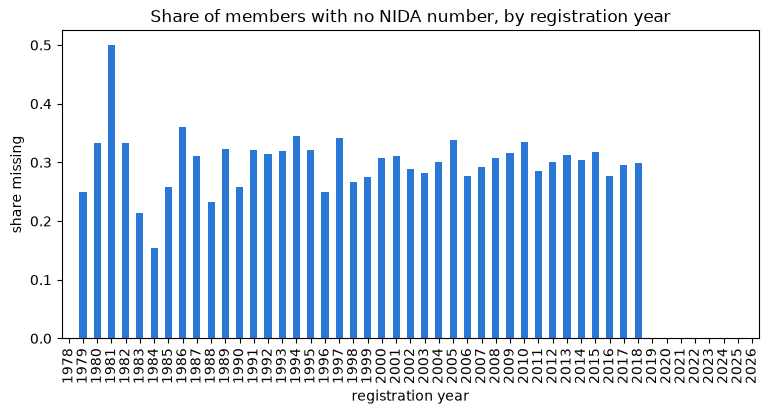

In [115]:
# Draw it as a bar chart.
nida_gap.plot(kind="bar", color="#2a78d6")
plt.title("Share of members with no NIDA number, by registration year")
plt.ylabel("share missing")
plt.xlabel("registration year")
plt.show()

Missing NIDA (National Identification Authority) numbers are concentrated among members registered before 2019. That fits with NIDA numbers
becoming a registration requirement later. It isn't random, so it's a **task** for the member
services team (update older records), not something to impute.

Same exercise for contributions:

In [116]:
# Missing values in the contributions table.
contrib_missing = pd.DataFrame({"missing": contrib.isna().sum(), "share": contrib.isna().mean()})
contrib_missing[contrib_missing["missing"] > 0]

,missing,share
gross_wages_tzs,767,0.01
amount_paid_tzs,3711,0.03
payment_date,3711,0.03


`amount_paid_tzs` and `payment_date` are missing together on the same rows. Those are months the
employer hasn't paid. In business terms they're **arrears**, and they're one of the most useful things in
this whole extract. `gross_wages_tzs` missing on a few rows is a different matter: the employer
submitted a schedule without wages. That's a genuine data gap.

In [117]:
# How many employer-months are unpaid?
unpaid = contrib["amount_paid_tzs"].isna()
print("Unpaid employer-months:", unpaid.sum())
print("Share of all employer-months:", round(unpaid.mean() * 100, 1), "%")

# Are amount and date always missing on the same rows?
no_date = contrib["payment_date"].isna()
print("Rows where only one of the two is missing:", (unpaid != no_date).sum())

Unpaid employer-months: 3711
Share of all employer-months: 2.9 %
Rows where only one of the two is missing: 0


> **Where we are.** You know which empty cells are real gaps and which are information. Now you'll look at the values
> that *are* there, one column at a time, to see their shape and spot the extremes.

### Theory: distributions, skew, and outliers

**A distribution** is the pattern of values in a column: where most of them sit, how spread out they are, and how far
the extremes reach. A **histogram** draws it: the values are cut into ranges ("bins"), and each bar shows how many fall
in that range.

**Skewed data.** Wages aren't spread evenly around an average. Most people earn a moderate amount and a few earn a lot,
so the histogram has a big hump on the left and a long thin tail to the right. That's called **right-skewed**. Money
amounts are almost always like this: wages, claim amounts, contributions.

**Why the median beats the mean for skewed data.** Take five monthly wages: 400k, 500k, 600k, 700k and 12 million.
The mean is 2.84 million, which describes nobody. The median (the middle value) is 600k, which describes a typical
member. One extreme value moves the mean a lot and the median not at all.

**The log scale.** A logarithm (base 10) counts the zeros: log10(1,000) = 3, log10(1,000,000) = 6. Plotting wages on a
log scale turns "times ten" into "plus one", so TZS 100,000, 1 million and 10 million sit at evenly spaced points. The
long tail shrinks and the shape of the hump becomes visible.

**Outlier or error?** An **outlier** is a value far from the rest. It could be real (a managing director's salary) or
an error (an extra zero). The data alone can't settle it. What helps is **context**: compare the value with similar
rows, such as other staff at the same employer. A wage ten times the employer's median, at an exact multiple of ten,
looks like a typing slip. Flag it for a person to check; don't "correct" it in code.

## 8. One variable at a time

### Wages

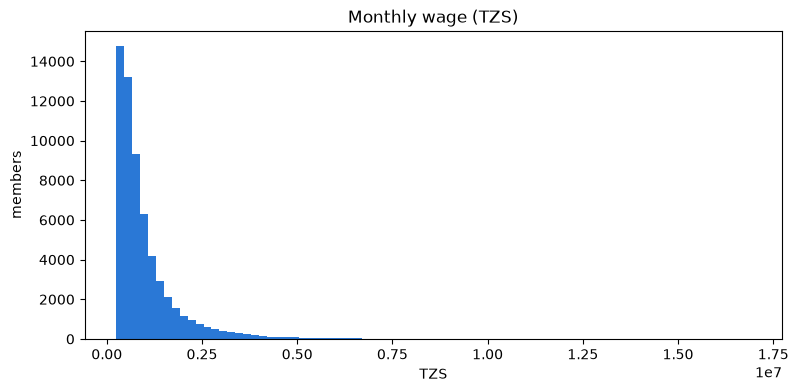

In [118]:
# Drop the missing wages, then draw a histogram (how many members fall in each wage range).
wages = members["monthly_wage_tzs"].dropna()

plt.hist(wages, bins=80, color="#2a78d6")
plt.title("Monthly wage (TZS)")
plt.xlabel("TZS")
plt.ylabel("members")
plt.show()

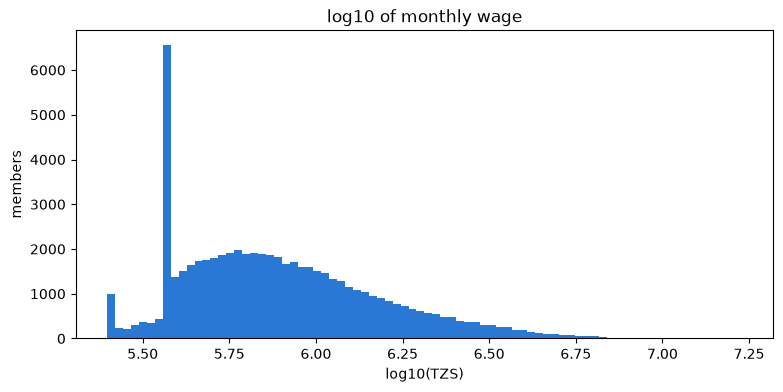

In [119]:
# The same data on a log scale: log10(1,000,000) = 6, log10(10,000,000) = 7.
# Each step of 1 on this axis means "ten times more".
plt.hist(np.log10(wages), bins=80, color="#2a78d6")
plt.title("log10 of monthly wage")
plt.xlabel("log10(TZS)")
plt.ylabel("members")
plt.show()

In [120]:
# The 1st percentile, median (50%) and 99th percentile tell you more than the mean for skewed data.
wages.describe(percentiles=[0.01, 0.5, 0.99])

count       60,840.00
mean       998,477.81
std        883,094.85
min        250,000.00
1%         250,000.00
50%        712,000.00
99%      4,583,830.00
max     16,900,000.00
Name: monthly_wage_tzs, dtype: float64

The raw histogram is almost useless: a few huge values squash everything else into one bar. On a log
scale you can see the real shape, a skewed distribution centred somewhere around TZS 600,000-800,000.
Wages are almost always skewed like this, which is why medians describe them better than means.

What about the extreme values?

In [121]:
# The 8 highest wages.
members.nlargest(8, "monthly_wage_tzs")[["member_no", "monthly_wage_tzs", "employer_no"]]

,member_no,monthly_wage_tzs,employer_no
2666,156248264,"16,900,000.00",ER507307
56318,539322186,"13,750,000.00",ER334205
38290,504885689,"13,334,000.00",ER262544
55415,415990119,"13,330,000.00",ER504669
42523,291747060,"12,034,000.00",ER233796
14817,510601943,"11,796,000.00",ER477562
10816,478569555,"11,663,000.00",ER358849
50742,504618314,"11,355,000.00",ER293169


Some of these end in an extra zero compared with the rest of their employer's staff. Compare each one
with the median wage at the same employer:

In [122]:
# For every member, the median wage of everyone at the same employer.
# groupby(...).transform("median") returns one value per ROW (not per employer), so it lines up with members.
members["employer_median_wage"] = members.groupby("employer_no")["monthly_wage_tzs"].transform("median")

# How many times the employer median is each member's wage?
members["wage_vs_employer"] = members["monthly_wage_tzs"] / members["employer_median_wage"]

# Show members earning 8 or more times their employer's median.
suspect = members[members["wage_vs_employer"] > 8]
suspect[["member_no", "employer_no", "monthly_wage_tzs", "employer_median_wage"]]

,member_no,employer_no,monthly_wage_tzs,employer_median_wage
1269,130385177,ER125499,"5,950,000.00","545,000.00"
2666,156248264,ER507307,"16,900,000.00","780,000.00"
4169,171965430,ER155695,"4,340,000.00","525,000.00"
9404,260672581,ER183574,"6,100,000.00","631,000.00"
14120,262699658,ER103680,"7,250,000.00","520,000.00"
34858,395828127,ER151652,"10,300,000.00","845,000.00"
36928,520473354,ER276404,"10,810,000.00","1,039,000.00"
44505,239136130,ER240388,"6,370,000.00","504,000.00"
55415,415990119,ER504669,"13,330,000.00","1,006,500.00"
56318,539322186,ER334205,"13,750,000.00","1,045,500.00"


A wage eight or more times the employer's median, at round multiples of ten, is very likely a typing
error. It could also be a managing director. That's the kind of call you **flag for someone to check**,
not something you "fix" in code.

### Ages

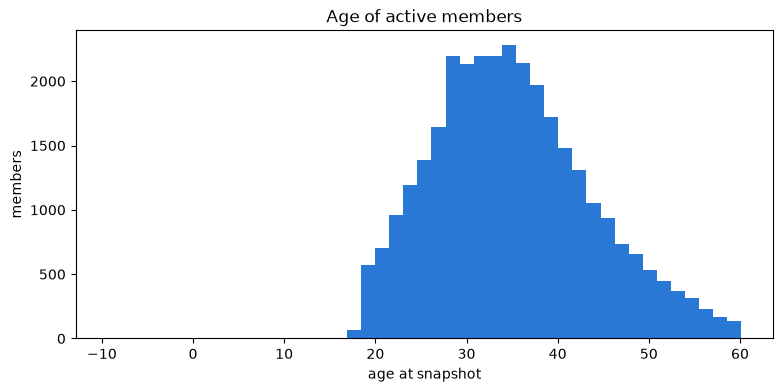

In [123]:
# Age at the snapshot date, in years.
members["age"] = (SNAPSHOT - members["date_of_birth"]).dt.days / 365.25

# Only active members.
active_members = members[members["status"] == "ACTIVE"]

plt.hist(active_members["age"].dropna(), bins=45, color="#2a78d6")
plt.title("Age of active members")
plt.xlabel("age at snapshot")
plt.ylabel("members")
plt.show()

### Claim amounts by benefit type

A single histogram of all claim amounts would mix TZS 500,000 funeral grants with multi-million pension
lump sums. Look at each benefit type separately:

In [124]:
# describe() for each benefit type, keeping four of its columns.
amount_by_benefit = claims.groupby("benefit_type", observed=True)["amount_claimed_tzs"].describe()
amount_by_benefit[["count", "min", "50%", "max"]]

,count,min,50%,max
benefit_type,,,,
EMPLOYMENT_INJURY,70.00,"500,000.00","3,150,000.00","5,800,000.00"
FUNERAL_GRANT,265.00,"500,000.00","500,000.00","5,000,000.00"
INVALIDITY_PENSION,122.00,"692,700.00","2,789,600.00","25,681,900.00"
MATERNITY,"3,784.00","576,600.00","1,929,200.00","23,822,400.00"
OLD_AGE_GRANT,291.00,"907,200.00","24,476,300.00","254,922,000.00"
OLD_AGE_PENSION,"1,122.00","813,800.00","23,405,850.00","220,529,600.00"
SURVIVORS_PENSION,271.00,"418,500.00","2,362,000.00","24,165,900.00"
UNEMPLOYMENT,"7,923.00","425,100.00","1,268,700.00","19,776,200.00"


**Your turn (4).** The funeral grant is a flat TZS 500,000. Which funeral grant claims have a different
amount? What do you think happened?

In [155]:
is_funeral = claims["benefit_type"] == "FUNERAL_GRANT"
wrong_amount = claims["amount_claimed_tzs"] != 500_000

claims.loc[is_funeral & wrong_amount, ["claim_no", "claim_date", "amount_claimed_tzs", "amount_paid_tzs", "status"]]

,claim_no,claim_date,amount_claimed_tzs,amount_paid_tzs,status
2769,CLM-2019-012729,2019-08-23,"5,000,000.00","5,000,000.00",PAID
3579,CLM-2020-008907,2020-04-16,"5,000,000.00","5,000,000.00",PAID
5275,CLM-2021-011941,2021-03-12,"5,000,000.00","5,000,000.00",PAID
7511,CLM-2022-000583,2022-08-05,"5,000,000.00","5,000,000.00",PAID
8730,CLM-2023-000411,2023-05-14,"5,000,000.00","5,000,000.00",PAID
11183,CLM-2024-002784,2024-10-10,"5,000,000.00","5,000,000.00",PAID


> **Where we are.** You've looked at the number columns one by one: wages are skewed with a few likely typing slips,
> ages and claim amounts have their own checks. Now you'll count the text columns (sector, region) and start grouping:
> the step from "what's in this column" to "how do groups compare".

### Theory: group-by in one picture

`groupby` is the most useful tool in pandas. It does three things, often called **split, apply, combine**:

```
split            apply (e.g. mean)       combine
sector=A: rows ─► mean of A ─┐
sector=B: rows ─► mean of B ─┼─► one small table: one row per sector
sector=C: rows ─► mean of C ─┘
```

`c.groupby("employer_no")["contribution_due_tzs"].mean()` means: split the contribution rows by employer, take the mean
amount due for each employer, and put the results together in one table with one row per employer.

`.agg(...)` lets you compute several summaries at once (the count of months, the average due, the average headcount),
each becoming one column of the result.

The grain changes when you group. The input had one row per employer per month; the output has one row per employer.
Always know which grain you're looking at.

## 9. Categories and groups

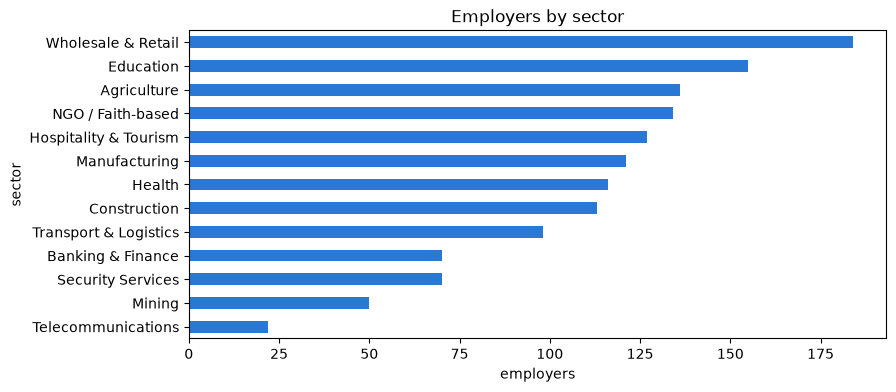

In [126]:
# Number of employers in each sector, as a horizontal bar chart.
sector_counts = employers["sector"].value_counts().sort_values()

sector_counts.plot(kind="barh", color="#2a78d6")
plt.title("Employers by sector")
plt.xlabel("employers")
plt.show()

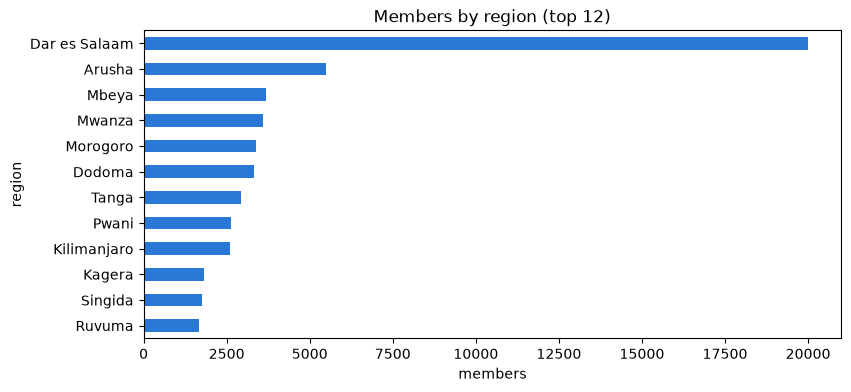

In [127]:
# Number of members in each region, top 12.
region_counts = members["region"].value_counts().head(12).sort_values()

region_counts.plot(kind="barh", color="#2a78d6")
plt.title("Members by region (top 12)")
plt.xlabel("members")
plt.show()

### Contributions per employer per month

Since the contributions table has one row per employer per month (once duplicates are dealt with), an
employer's typical monthly contribution is a simple group-by. For now, drop exact duplicates and the
reversal rows so that you're not double counting. You'll do this properly in Lab 3.

In [128]:
# A quick, rough clean-up for exploring (Lab 3 does this properly):
# 1. drop rows that are exact copies
c = contrib.drop_duplicates()

# 2. drop the negative reversal rows
c = c[c["amount_paid_tzs"].isna() | (c["amount_paid_tzs"] >= 0)]

# 3. keep one row per employer-month
c = c.drop_duplicates(subset=["employer_no", "period"])
print("rows left:", len(c))

rows left: 127343


In [129]:
# For each employer: number of months, average contribution due, and average members reported.
per_employer = c.groupby("employer_no").agg(
    months=("period", "nunique"),
    avg_due=("contribution_due_tzs", "mean"),
    avg_members=("members_reported", "mean"),
)

# Largest contributors first.
per_employer.sort_values("avg_due", ascending=False).head(10)

,months,avg_due,avg_members
employer_no,,,
ER322374,108,"87,637,170.37",223.62
ER165071,20,"69,617,520.00",133.05
ER183574,36,"64,252,450.00",469.53
ER407110,46,"62,529,417.39",117.70
ER377522,108,"52,581,362.96",235.62
ER543984,41,"49,594,707.32",85.22
ER358849,84,"48,446,016.67",83.42
ER126883,108,"47,493,216.67",79.44
ER240546,108,"42,413,718.52",197.84


### Claims per benefit type and region

In [130]:
# Claims don't have a region, but members do. Keep one row per member, then join the region onto each claim.
members_one_row = members.drop_duplicates(subset=["member_no"])

claims_with_region = claims.merge(members_one_row[["member_no", "region"]], on="member_no", how="left")

# crosstab counts claims for every (region, benefit type) pair.
region_by_benefit = pd.crosstab(claims_with_region["region"], claims_with_region["benefit_type"])

# Add a total column, sort by it, and show the 10 busiest regions.
region_by_benefit["total"] = region_by_benefit.sum(axis=1)
region_by_benefit.sort_values("total", ascending=False).head(10)

benefit_type,EMPLOYMENT_INJURY,FUNERAL_GRANT,INVALIDITY_PENSION,MATERNITY,OLD_AGE_GRANT,OLD_AGE_PENSION,SURVIVORS_PENSION,UNEMPLOYMENT,total
region,,,,,,,,,
Dar es Salaam,23,84,43,1257,109,359,85,2527,4487
Arusha,7,19,9,315,20,114,22,709,1215
Mwanza,6,19,6,231,14,57,17,480,830
Mbeya,4,21,6,214,17,82,17,439,800
Dodoma,0,12,5,213,20,58,11,481,800
Tanga,3,11,11,196,11,51,9,389,681
Morogoro,5,14,8,201,9,42,17,382,678
Pwani,4,5,5,164,12,54,9,339,592
Kilimanjaro,3,16,2,148,18,41,16,323,567


### Theory: reading a time series

A **time series** is a set of values measured at regular points in time: here, one total per month. When you plot one,
look for four things:

- **Trend:** the long-run direction. Contributions due rise over the years as membership and wages grow.
- **Seasonality:** a pattern that repeats every year in the same months. At the Fund, more cash arrives in June
  because of the year-end compliance drive.
- **Steps:** a sudden permanent jump, usually caused by a rule change (a new wage floor, a new contribution rate).
- **Shocks:** a temporary dip or spike with an outside cause, such as COVID-19 in 2020.

**Two clocks in one table.** Each contribution row has a **wage month** (`period`, the month the wages were earned) and
a **payment date** (when the money arrived). Grouping by wage month tells you what was *owed* each month. Grouping by
payment month tells you what *arrived* each month. These are different series with different shapes, and Day 4's
forecasts need to know which one finance means.

**On-time rate.** A payment is on time if it arrived by the due date (the last day of the month after the wage month).
The on-time rate for a month is the share of employers whose payment for that month was on time.

## 10. Time: trends, seasons and late payment

Contributions are due by the last day of the month after the wage month. How much is due each month, and
how much of it arrives on time?

In [131]:
# Turn the period text "2024-03" into a real date: the first day of that month.
c["period_start"] = pd.to_datetime(c["period"] + "-01")

# Days between the due date and the payment date. Negative = paid early.
c["days_late"] = (c["payment_date"] - c["due_date"]).dt.days

# Paid on time? (True / False)
c["on_time"] = c["days_late"] <= 0

c[["employer_no", "period", "due_date", "payment_date", "days_late", "on_time"]].head()

,employer_no,period,due_date,payment_date,days_late,on_time
0,ER273961,2025-11,2025-12-31,2025-12-12,-19.00,True
1,ER399920,2017-07,2017-08-31,2017-08-07,-24.00,True
2,ER322374,2025-02,2025-03-31,2025-04-09,9.00,False
3,ER441694,2019-06,2019-07-31,2019-07-25,-6.00,True
4,ER232559,2020-01,2020-02-29,2020-02-10,-19.00,True


In [132]:
# One row per month: total due, total paid, and the share of employers paying on time.
monthly = c.groupby("period_start").agg(
    due=("contribution_due_tzs", "sum"),
    paid=("amount_paid_tzs", "sum"),
    on_time=("on_time", "mean"),
)
monthly.head()

,due,paid,on_time
period_start,,,
2017-01-01,"3,093,106,600.00","2,980,112,564.00",0.59
2017-02-01,"3,083,899,200.00","3,018,474,405.00",0.57
2017-03-01,"3,044,203,600.00","2,936,334,838.00",0.58
2017-04-01,"3,014,545,000.00","2,926,475,562.00",0.57
2017-05-01,"3,023,089,800.00","2,946,884,011.00",0.58


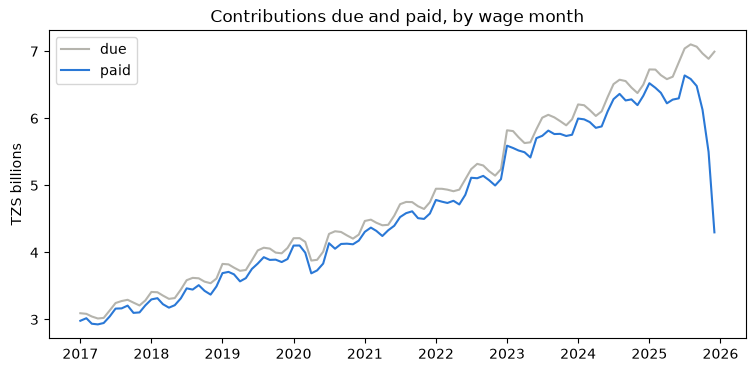

In [133]:
# Plot due and paid, in billions of TZS.
plt.plot(monthly.index, monthly["due"] / 1e9, color="#b5b4ad", label="due")
plt.plot(monthly.index, monthly["paid"] / 1e9, color="#2a78d6", label="paid")
plt.title("Contributions due and paid, by wage month")
plt.ylabel("TZS billions")
plt.legend()
plt.show()

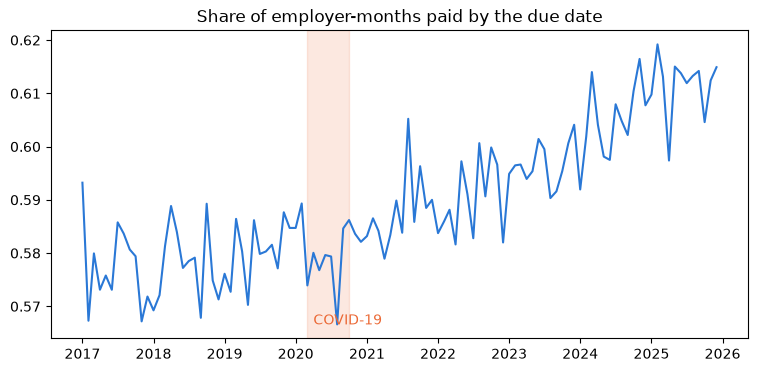

In [134]:
# Plot the on-time share, and shade the COVID-19 months.
plt.plot(monthly.index, monthly["on_time"], color="#2a78d6")
plt.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-10-01"), color="#eb6834", alpha=0.15)
plt.text(pd.Timestamp("2020-04-01"), monthly["on_time"].min(), "COVID-19", color="#eb6834")
plt.title("Share of employer-months paid by the due date")
plt.show()

Two things stand out. The steady growth in the amount due (more members, higher wages, and a step in
January 2023) and a clear dip in on-time payment in 2020.

Now look at **when** payments actually arrive, by calendar month of the payment date:

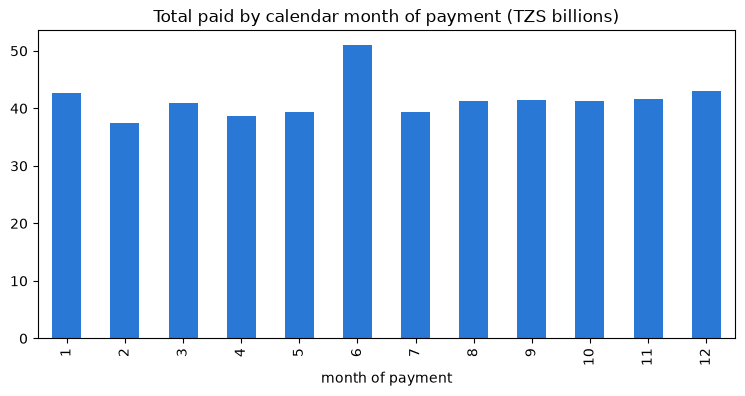

In [135]:
# Keep only rows that were paid, and add the calendar month (1-12) of the payment.
paid_rows = c[c["payment_date"].notna()].copy()
paid_rows["payment_month"] = paid_rows["payment_date"].dt.month

# Total paid in each calendar month, in billions.
paid_by_month = paid_rows.groupby("payment_month")["amount_paid_tzs"].sum() / 1e9

paid_by_month.plot(kind="bar", color="#2a78d6")
plt.title("Total paid by calendar month of payment (TZS billions)")
plt.xlabel("month of payment")
plt.show()

June stands out. The Fund's financial year ends on 30 June, and a compliance drive before year-end pulls in
old arrears. It matters for Day 4: if you forecast *cash received*, June behaves differently from other
months; if you forecast *contributions due*, it doesn't.

**Your turn (5).** Which sector has the worst on-time payment rate? Join `c` to `employers` on
`employer_no` and compute the on-time share by sector, from worst to best.

In [136]:
# Your code here

> **Where we are.** So far you've looked at each table on its own. Many of the most useful questions need two tables
> together: "which regions lodge the most claims?" needs claims (no region) and members (with region). That means
> joining.

### Theory: how a join works, and how it goes wrong

A **join** (pandas calls it `merge`) lines up rows from two tables that share a key. For every claim, pandas looks up
the member with the same `member_no` and copies that member's columns onto the claim row.

**Left join.** `how="left"` keeps every row of the left table (claims), whether or not it finds a match. If a claim's
member isn't found, the member columns are left empty. That's what you want here: you mustn't lose claims just because
a member record is missing.

**Three ways a join goes wrong**, all silently:

| Problem | What happens | How to catch it |
|---|---|---|
| **Duplicate keys on the right** | a claim matches two member rows and appears twice | compare row counts before and after |
| **No match** | the claim keeps empty member columns | `indicator=True` adds a `_merge` column saying `both` or `left_only` |
| **Clashing column names** | both tables have `status`, pandas renames them `status_x` and `status_y` | rename before joining |

The rule: **count the rows before and after every join, and look at the rows that didn't match.** The unmatched rows
are often the most interesting finding of the day.

## 11. Joining tables, and checking the joins

Every join is a place where rows can quietly appear or disappear. Always compare row counts before and
after, and look at what didn't match.

In [137]:
# The member columns we want on each claim. Both tables have a "status" column, so rename the member one.
member_cols = members_one_row[["member_no", "gender", "date_of_birth", "date_of_death", "status"]]
member_cols = member_cols.rename(columns={"status": "member_status"})

# Join. how="left" keeps every claim. indicator=True adds a "_merge" column saying where each row matched.
rows_before = len(claims)
cm = claims.merge(member_cols, on="member_no", how="left", indicator=True)

print("rows before:", rows_before)
print("rows after: ", len(cm))
cm["_merge"].value_counts()

rows before: 13848
rows after:  13848


_merge
both          13813
left_only        35
right_only        0
Name: count, dtype: int64

Both tables have a `status` column (claim status and member status), so the member one is renamed before
the join. Otherwise pandas would call them `status_x` and `status_y`, and nobody would remember which is
which.

The row count didn't change, which means `member_no` is unique on the right-hand side. That's why you
dropped the duplicate members first. If you hadn't, every claim by a duplicated member would have
been counted twice.

But some claims have no matching member at all:

In [138]:
# "left_only" = the claim found no member.
orphans = cm[cm["_merge"] == "left_only"]
print(len(orphans), "claims for member numbers that don't exist in the members table")
orphans[["claim_no", "member_no", "benefit_type", "claim_date", "amount_paid_tzs", "status"]].head()

35 claims for member numbers that don't exist in the members table


,claim_no,member_no,benefit_type,claim_date,amount_paid_tzs,status
2360,CLM-2019-800020,248065685,UNEMPLOYMENT,2019-04-12,"1,273,700.00",PAID
2447,CLM-2019-800027,990176867,UNEMPLOYMENT,2019-05-09,"2,427,100.00",PAID
2474,CLM-2019-800015,861111004,MATERNITY,2019-05-16,"2,880,000.00",PAID
2498,CLM-2019-800014,531894240,MATERNITY,2019-05-23,"604,100.00",PAID
2575,CLM-2019-800011,451487241,UNEMPLOYMENT,2019-06-17,"2,052,100.00",PAID


### Theory: correlation in plain words

**Correlation** is one number between -1 and +1 that says how closely two columns move together:

| Value | Meaning | Example |
|---|---|---|
| close to +1 | when one is high, the other is high | headcount and total wages |
| close to 0 | no straight-line relationship | shoe size and on-time payment |
| close to -1 | when one is high, the other is low | days late and on-time share |

Three cautions:

- **Correlation isn't cause.** Large employers might pay on time because they have finance departments, or because
  the Fund chases them harder. The number can't tell you which.
- **It only sees straight lines.** A relationship that goes up and then down can have a correlation near 0.
- **Skewed columns distort it.** A few huge employers can dominate. Taking the logarithm of headcount first (as the
  code does) gives the many small employers a fair say.

Paid claims for members who don't exist are a serious finding. It might be a migration gap between
systems, or it might be something worse. Either way, that list goes to the claims team.

## 12. Relationships between variables

Do small employers pay late more often than large ones? Band employers by average headcount and compare:

In [139]:
# One row per employer: average headcount and share of months paid on time.
emp_stats = c.groupby("employer_no").agg(
    avg_members=("members_reported", "mean"),
    on_time=("on_time", "mean"),
)

# pd.cut puts each employer into a size band.
emp_stats["size_band"] = pd.cut(
    emp_stats["avg_members"],
    bins=[0, 5, 20, 100, 10_000],
    labels=["1-5", "6-20", "21-100", "100+"],
)

# Average on-time share, and number of employers, per band.
emp_stats.groupby("size_band", observed=True)["on_time"].agg(["mean", "count"])

,mean,count
size_band,,
1-5,0.59,350
6-20,0.61,658
21-100,0.56,357
100+,0.41,35


In [140]:
# Correlation: +1 = move together perfectly, 0 = no relationship, -1 = opposite directions.
# Headcount is very skewed, so use its log. clip(lower=1) avoids log(0).
log_headcount = np.log(emp_stats["avg_members"].clip(lower=1))
correlation = log_headcount.corr(emp_stats["on_time"])
print("Correlation between log(headcount) and on-time share:", round(correlation, 3))

Correlation between log(headcount) and on-time share: -0.039


> **Where we are.** You've profiled, de-duplicated, typed, grouped, joined and correlated. The data is now good enough
> to ask business questions of it. This section looks for patterns that may point to real problems: claims and
> payments that a person in the business should look at.

### Theory: a rule, a flag, and a decision

The checks in this section are **rules**: simple tests like "claim lodged after the member's recorded death". A rule
produces a **flag**: a list of rows that match. A flag is *not* a finding of wrongdoing. Each flagged row needs a
person who knows the business to make the **decision**.

A good rule balances two kinds of mistake:

- **Too broad**, and it flags thousands of legitimate rows (every funeral grant comes after a death, by design). The
  team stops trusting the list.
- **Too narrow**, and it misses real cases.

Getting that balance right is the heart of Day 2's risk model and Day 5's fraud detection. Here you're doing it by
hand, with rules you can read.

The relationship is weak. Size alone doesn't tell you much about payment behaviour. That's a useful
result: it tells you a compliance model on Day 2 will need more than headcount.

## 13. Signals worth a closer look

These aren't conclusions. They're patterns that someone who knows the business should look at.

**Claims lodged after the member's recorded death**, for benefits that the member would have to claim
personally:

In [141]:
# Benefits a member has to claim in person.
personal = ["MATERNITY", "UNEMPLOYMENT", "OLD_AGE_PENSION", "OLD_AGE_GRANT", "INVALIDITY_PENSION"]

# Three conditions, each a True/False column.
has_death_date = cm["date_of_death"].notna()
claimed_after_death = cm["claim_date"] > cm["date_of_death"]
is_personal = cm["benefit_type"].isin(personal)

# & means "and": all three must be True.
after_death = cm[has_death_date & claimed_after_death & is_personal]
print(len(after_death), "claims")
after_death[["claim_no", "member_no", "benefit_type", "date_of_death", "claim_date", "amount_paid_tzs", "branch"]].head(8)

24 claims


,claim_no,member_no,benefit_type,date_of_death,claim_date,amount_paid_tzs,branch
1871,CLM-2018-900012,517421979,MATERNITY,2018-02-16,2018-11-09,"1,678,300.00",Temeke
3222,CLM-2020-003056,425099077,UNEMPLOYMENT,2019-12-16,2020-01-06,0.00,Ilala
4506,CLM-2020-900014,213891278,UNEMPLOYMENT,2020-05-23,2020-08-18,"4,361,400.00",Temeke
5150,CLM-2021-900017,283105471,OLD_AGE_PENSION,2020-08-09,2021-02-08,"1,001,500.00",Temeke
5659,CLM-2021-900005,352679296,OLD_AGE_PENSION,2020-07-25,2021-05-31,"4,485,900.00",Temeke
6054,CLM-2021-900007,329939708,UNEMPLOYMENT,2021-03-24,2021-09-07,"3,350,200.00",Temeke
7247,CLM-2022-001505,418251006,UNEMPLOYMENT,2022-05-29,2022-06-02,"773,200.00",Iringa
7759,CLM-2022-900004,368009869,OLD_AGE_PENSION,2022-02-10,2022-10-12,"1,274,800.00",Temeke


Notice that survivors' pensions and funeral grants are excluded on purpose: those are *supposed* to come
after a death. A rule that flags every claim after a death would bury the real cases in false alarms.

**Maternity claims by members recorded as male:**

In [142]:
is_maternity = cm["benefit_type"] == "MATERNITY"
is_male = cm["gender"] == "M"

maternity_male = cm[is_maternity & is_male]
maternity_male[["claim_no", "member_no", "claim_date", "amount_paid_tzs", "branch"]]

,claim_no,member_no,claim_date,amount_paid_tzs,branch
5764,CLM-2021-700000,513627793,2021-06-23,"2,900,800.00",Kinondoni
7420,CLM-2022-700003,201865186,2022-07-11,"4,121,600.00",Kinondoni
7532,CLM-2022-700007,343346367,2022-08-09,"2,436,000.00",Dodoma
7807,CLM-2022-700009,237643773,2022-10-24,"6,795,600.00",Dodoma
8323,CLM-2023-700008,197303351,2023-02-11,"6,216,000.00",Dodoma
9937,CLM-2024-700002,521492810,2024-01-17,"2,013,200.00",Dodoma
11017,CLM-2024-700004,290068142,2024-09-01,"4,300,800.00",Dodoma
11063,CLM-2024-700001,271509859,2024-09-14,"1,864,800.00",Kinondoni
11585,CLM-2024-700005,529484422,2024-12-20,"1,612,800.00",Kinondoni
11635,CLM-2024-700006,245324147,2024-12-29,"1,825,600.00",Kinondoni


It could be a gender data error in the member record, or a claim against the wrong member number.
Either way, a person should look at it.

**Employers still trading but falling behind.** Count unpaid months in 2025 for employers recorded as
ACTIVE. Be careful with the most recent months: December's contributions were only due on 31 January,
the day of the extract, so "unpaid" there mostly means "not due yet". Only count months that were at least
30 days overdue when the extract was taken.

In [143]:
# Months from January 2025 that were due at least 30 days before the snapshot.
cutoff = SNAPSHOT - pd.Timedelta(days=30)
recent = c[(c["period_start"] >= "2025-01-01") & (c["due_date"] <= cutoff)].copy()

# Mark the unpaid months, then count them per employer.
recent["unpaid"] = recent["amount_paid_tzs"].isna()
unpaid_per_employer = recent.groupby("employer_no")["unpaid"].sum()
unpaid_per_employer.head()

employer_no
ER100000    0
ER100330    0
ER100826    6
ER100849    0
ER100904    0
Name: unpaid, dtype: int64

In [144]:
# The employer numbers of ACTIVE employers.
active_employer_nos = employers.loc[employers["status"] == "ACTIVE", "employer_no"]

# Employers with 3 or more unpaid months...
three_or_more = unpaid_per_employer[unpaid_per_employer >= 3]

# ...that are still ACTIVE.
behind = three_or_more[three_or_more.index.isin(active_employer_nos)]
print(len(behind), "active employers with 3 or more overdue unpaid months in 2025")
behind.sort_values(ascending=False).head(8)

139 active employers with 3 or more overdue unpaid months in 2025


employer_no
ER426757    9
ER107042    8
ER494326    8
ER505659    7
ER500164    7
ER488511    7
ER140202    7
ER416878    7
Name: unpaid, dtype: int64

Each of those employers has staff whose statements are missing months, and some of those staff will
end up at a branch complaining (you'll meet their complaints on Day 6). A list like this is what a
compliance officer wants on a Monday morning.

> **Where we are.** You now know this data better than most people who use it. You've found duplicates, impossible
> dates, inconsistent spellings, meaningful gaps, probable typing errors, orphaned claims and payment patterns. All of
> that is still only in this notebook.

### Theory: why an issues log

An **issues log** is a simple table with one row per data problem: which table, which column, what's wrong, how many
rows, and what to do about it. It does three jobs:

1. **It's shareable.** The data owners (member services, finance, claims) can read it without opening Python.
2. **It's trackable.** Each issue can be given an owner and marked fixed.
3. **It becomes code.** In Lab 3, each "what to do" column turns into a cleaning rule in the pipeline. The log is the
   specification for that code.

## 14. Write it down: the issues log

Findings that live only in your head, or in a notebook nobody reads, get lost. Put them in a table that
you can share, track and turn into pipeline rules in Lab 3.

First work out the counts you'll quote, one per line, so you can check each number:

In [145]:
n_dup_members = members.duplicated(subset=["member_no"]).sum()
n_bad_dob = too_young.sum()
n_wage_outliers = len(suspect)
n_no_nida = members["nida_no"].isna().sum()
n_dup_employers = employers.duplicated(subset=["employer_no"]).sum()
n_exact_dup_contrib = contrib.duplicated().sum()
n_negative = (contrib["amount_paid_tzs"] < 0).sum()
n_future_payment = (contrib["payment_date"] > SNAPSHOT).sum()
n_no_wages = contrib["gross_wages_tzs"].isna().sum()
n_orphans = len(orphans)
n_after_death = len(after_death)

is_funeral = claims["benefit_type"] == "FUNERAL_GRANT"
n_wrong_funeral = (is_funeral & (claims["amount_claimed_tzs"] != 500_000)).sum()

In [146]:
# One list per issue: table, column, what's wrong, rows affected, what to do.
issues = pd.DataFrame(
    [
        ["members", "member_no", "Duplicate member rows differing only in phone format", n_dup_members, "Standardise phone to +255, keep one row per member_no"],
        ["members", "region", "Several spellings of Dar es Salaam; case and spacing variants", None, "Map to canonical region names"],
        ["members", "gender", "Mixed codes (F/M/Female/male) and missing", None, "Standardise to F/M; leave missing as missing"],
        ["members", "date_of_birth", "Birth dates giving age under 15 at registration", n_bad_dob, "Set to missing and flag for correction"],
        ["members", "monthly_wage_tzs", "Wages 8x+ the employer median, likely extra zero", n_wage_outliers, "Flag for review; don't auto-correct"],
        ["members", "nida_no", "Missing, mostly for pre-2019 registrations", n_no_nida, "Member services data-update task"],
        ["employers", "employer_no", "Duplicate employer rows with upper-case names", n_dup_employers, "Keep one row per employer_no"],
        ["contributions", "employer_no+period", "Exact duplicate rows", n_exact_dup_contrib, "Drop exact duplicates, but only where there's no reversal"],
        ["contributions", "amount_paid_tzs", "Negative amounts: reversals of double postings", n_negative, "Net payments per employer-month"],
        ["contributions", "payment_date", "Payment dates after the snapshot (typed 22xx)", n_future_payment, "Set to missing and flag"],
        ["contributions", "gross_wages_tzs", "Missing on some schedules", n_no_wages, "Derive from contribution_due / 0.2"],
        ["claims", "benefit_type", "Inconsistent labels", None, "Standardise to upper-case codes"],
        ["claims", "member_no", "Claims for member numbers not in members table", n_orphans, "Refer to claims team"],
        ["claims", "claim_date", "Personal benefit claims after recorded death", n_after_death, "Refer to claims/fraud team"],
        ["claims", "amount_claimed_tzs", "Funeral grants not equal to TZS 500,000", n_wrong_funeral, "Check against payment records"],
    ],
    columns=["table", "column", "issue", "rows_affected", "proposed_action"],
)
issues

,table,column,issue,rows_affected,proposed_action
0,members,member_no,Duplicate member rows differing only in phone ...,120.00,"Standardise phone to +255, keep one row per me..."
1,members,region,Several spellings of Dar es Salaam; case and s...,NaN,Map to canonical region names
2,members,gender,Mixed codes (F/M/Female/male) and missing,NaN,Standardise to F/M; leave missing as missing
3,members,date_of_birth,Birth dates giving age under 15 at registration,20.00,Set to missing and flag for correction
4,members,monthly_wage_tzs,"Wages 8x+ the employer median, likely extra zero",10.00,Flag for review; don't auto-correct
5,members,nida_no,"Missing, mostly for pre-2019 registrations","7,207.00",Member services data-update task
6,employers,employer_no,Duplicate employer rows with upper-case names,8.00,Keep one row per employer_no
7,contributions,employer_no+period,Exact duplicate rows,534.00,"Drop exact duplicates, but only where there's ..."
8,contributions,amount_paid_tzs,Negative amounts: reversals of double postings,25.00,Net payments per employer-month
9,contributions,payment_date,Payment dates after the snapshot (typed 22xx),10.00,Set to missing and flag


In [147]:
# Save the log as a CSV file in a "reports" folder (created if it doesn't exist).
Path("reports").mkdir(exist_ok=True)
issues.to_csv("reports/data_quality_issues_log.csv", index=False)
print("Saved reports/data_quality_issues_log.csv")

Saved reports/data_quality_issues_log.csv


**Your turn (6).** Add at least two rows of your own from what you noticed in *Your turn (1)* and the rest
of the notebook.

In [148]:
# Your code here

## 15. Questions to take back to the business

Good exploration ends with better questions, not only cleaner data. Here's a starting list. Add at least two of
your own, and keep the list: you'll come back to it on Day 10 when you prioritise what the Fund should build.

1. Are the 30-odd paid claims for unknown member numbers a migration problem or something else? Who owns
   that check today?
2. Should active employers with three or more unpaid months go straight to the compliance team's follow-up
   list? Who decides the threshold?
3. The June payment peak comes from the year-end compliance drive. Would finance prefer forecasts of
   contributions *due* or of cash *received*? (You'll need the answer on Day 4.)
4. What share of members registered before 2019 still lack a NIDA number, and is that blocking anything,
   for example digital life verification?
5. Which of the issues above should be fixed at the source system, rather than cleaned downstream every
   month?

---

## Answers to the "Your turn" exercises

Try each one yourself first. These are one way of doing it; yours may be different and still right.

**(1)** There's no single right answer. Things people usually notice: `amount_paid_tzs` has negative
values and a lot of missing values; `members_reported` has a minimum of 0; `contribution_months` goes into
the hundreds for long-serving members; `monthly_wage_tzs` has a very large maximum.

In [158]:
contrib.describe()

,members_reported,gross_wages_tzs,contribution_due_tzs,amount_paid_tzs,due_date,payment_date
count,"127,902.00","127,135.00","127,902.00","124,191.00",127902,124191
mean,20.00,"20,472,131.66","4,094,247.29","4,025,605.25",2021-10-27 22:33:11.762443,2021-11-02 11:59:51.999420
min,0.00,"250,000.00","50,000.00","-30,977,400.00",2017-02-28 00:00:00,2017-02-04 00:00:00
25%,5.00,"3,941,000.00","788,200.00","767,600.00",2019-08-31 00:00:00,2019-08-22 00:00:00
50%,10.00,"9,107,000.00","1,821,400.00","1,787,800.00",2021-11-30 00:00:00,2021-12-02 00:00:00
75%,22.00,"21,380,000.00","4,274,000.00","4,168,000.00",2024-01-31 00:00:00,2024-01-19 00:00:00
max,661.00,"668,490,000.00","133,698,000.00","133,126,000.00",2026-01-31 00:00:00,2225-10-30 00:00:00
std,31.60,"35,361,983.43","7,073,013.88","6,992,543.07",NaN,NaN


**(2)** Near-duplicate claims:

In [150]:
# Sort so each member's claims for the same benefit sit together, oldest first.
sorted_claims = claims.sort_values(["member_no", "benefit_type", "claim_date"])

# diff() = days since the previous claim in the same (member, benefit) group. The first one in a group is empty.
gap = sorted_claims.groupby(["member_no", "benefit_type"], observed=True)["claim_date"].diff()
sorted_claims["days_since_previous"] = gap.dt.days

near_dupes = sorted_claims[sorted_claims["days_since_previous"] < 10]
print(len(near_dupes), "claims lodged within 10 days of an earlier claim for the same benefit by the same member")
near_dupes[["claim_no", "member_no", "benefit_type", "claim_date", "amount_claimed_tzs", "status"]].head()

32 claims lodged within 10 days of an earlier claim for the same benefit by the same member


,claim_no,member_no,benefit_type,claim_date,amount_claimed_tzs,status
466,CLM-2017-504112,106128478,OLD_AGE_PENSION,2017-08-27,"22,607,300.00",PAID
5075,CLM-2021-500005,110872077,OLD_AGE_PENSION,2021-01-19,"13,353,700.00",PAID
6332,CLM-2021-510109,134339043,UNEMPLOYMENT,2021-11-09,"627,400.00",PAID
10473,CLM-2024-500031,135829267,UNEMPLOYMENT,2024-05-08,"7,442,600.00",PAID
8343,CLM-2023-506529,243286592,UNEMPLOYMENT,2023-02-17,"2,287,700.00",PAID


**(3)** See the cells right after the exercise.

**(4)** Funeral grants with the wrong amount:

In [159]:
is_funeral = claims["benefit_type"] == "FUNERAL_GRANT"
wrong_amount = claims["amount_claimed_tzs"] != 500_000

claims.loc[is_funeral & wrong_amount, ["claim_no", "claim_date", "amount_claimed_tzs", "amount_paid_tzs", "status"]]

,claim_no,claim_date,amount_claimed_tzs,amount_paid_tzs,status
2769,CLM-2019-012729,2019-08-23,"5,000,000.00","5,000,000.00",PAID
3579,CLM-2020-008907,2020-04-16,"5,000,000.00","5,000,000.00",PAID
5275,CLM-2021-011941,2021-03-12,"5,000,000.00","5,000,000.00",PAID
7511,CLM-2022-000583,2022-08-05,"5,000,000.00","5,000,000.00",PAID
8730,CLM-2023-000411,2023-05-14,"5,000,000.00","5,000,000.00",PAID
11183,CLM-2024-002784,2024-10-10,"5,000,000.00","5,000,000.00",PAID


TZS 5,000,000 is 500,000 with an extra zero. If these were *paid* at that amount, it's an overpayment
to recover. That's a question for finance, and a good argument for a validation rule at data entry.

**(5)** On-time rate by sector:

In [157]:
# Add each employer's sector to the contribution rows.
employers_one_row = employers.drop_duplicates(subset=["employer_no"])
c_with_sector = c.merge(employers_one_row[["employer_no", "sector"]], on="employer_no", how="left")

# Average on-time share per sector, worst first.
c_with_sector.groupby("sector")["on_time"].mean().sort_values()

sector
Security Services       0.02
Education               0.57
Mining                  0.57
Health                  0.59
Transport & Logistics   0.60
Agriculture             0.61
NGO / Faith-based       0.62
Wholesale & Retail      0.63
Hospitality & Tourism   0.64
Manufacturing           0.64
Construction            0.66
Banking & Finance       0.67
Telecommunications      0.72
Name: on_time, dtype: float64

**(6)** Your own rows, for example:

In [156]:
n_zero_members = (contrib["members_reported"] == 0).sum()
n_maternity_male = len(maternity_male)

extra = pd.DataFrame(
    [
        ["contributions", "members_reported", "Zero members reported with non-zero wages", n_zero_members, "Query employer schedule"],
        ["claims", "gender vs benefit", "Maternity claims against male member records", n_maternity_male, "Check member record and claim"],
    ],
    columns=issues.columns,
)

# pd.concat stacks two tables on top of each other.
issues_extended = pd.concat([issues, extra], ignore_index=True)
issues_extended.tail(3)

,table,column,issue,rows_affected,proposed_action
14,claims,amount_claimed_tzs,"Funeral grants not equal to TZS 500,000",6.00,Check against payment records
15,contributions,members_reported,Zero members reported with non-zero wages,5.00,Query employer schedule
16,claims,gender vs benefit,Maternity claims against male member records,10.00,Check member record and claim


## Looking back, looking ahead

**What you did in this lab.** You took four raw tables and, step by step:

1. learned how pandas stores data and why column types matter;
2. loaded the tables with IDs kept as text;
3. checked the grain of each table and found exact duplicates, key duplicates and reversals;
4. turned dates into real dates, found impossible ones, and standardised categories;
5. worked out *why* values were missing instead of filling them in;
6. looked at distributions and found probable typing errors in wages and claim amounts;
7. joined claims to members and found claims with no member at all;
8. wrote everything into an issues log and a list of questions for the business.

**What carries forward.** The issues log in `reports/` is the input to Lab 3. There you'll build a pipeline that
applies a fix for each issue in a fixed order, so that anyone can rerun it on next month's extract and get the same
clean tables.

**Where it leads.** The clean claims feed Day 2's risk score, the clean contributions feed Day 4's forecasts, and the
habits you practised here (check the grain, count before and after, ask why it's missing) are the ones you'll use on
every dataset for the rest of the course.